C:\Users\congc\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


DEVICE: cpu
0 0.5441396832466125
200 0.5089277625083923
400 0.4940381646156311
600 0.49115273356437683
800 0.4896329343318939
1000 0.4883749783039093
1200 0.4875253438949585
1400 0.4807545244693756
1600 0.475273460149765
1800 0.4687187671661377
2000 0.46074676513671875
2200 0.4401435852050781
2400 0.37367379665374756
2600 0.3326886296272278
2800 0.2895817160606384

RMSE: 0.4877537301181777
CORR: 0.7589870391057573


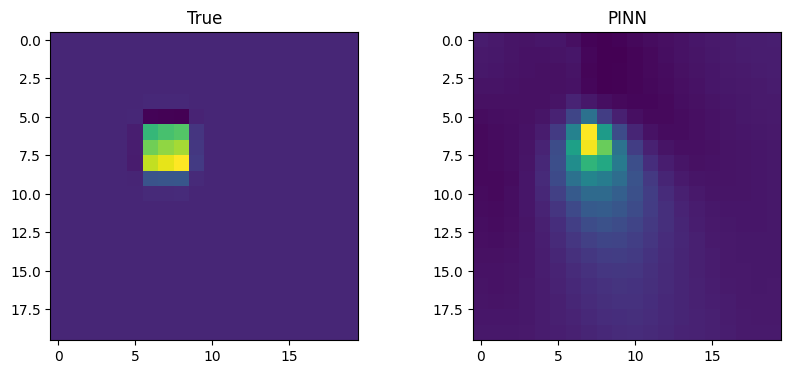

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from scipy.stats import qmc
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

import matplotlib.pyplot as plt

# ==================================================
# DEVICE
# ==================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", device)

# ==================================================
# GRID
# ==================================================

NX = 20
NY = 20
NT = 15

dx = 1.0
dy = 1.0
dt = 0.03

x = np.linspace(0,1,NX)
y = np.linspace(0,1,NY)
t = np.linspace(0,1,NT)

X,Y,T = np.meshgrid(
    x,
    y,
    t,
    indexing="ij"
)

# ==================================================
# TRUE TRANSPORT
# ==================================================

TRUE_DIFF = 0.05

def true_vx(x):
    return 1 + 0.5*x

def true_vy(y):
    return 0.3 + 0.2*y

# ==================================================
# GENERATE FIELD
# ==================================================

def simulate_transport():

    u = np.zeros((NX,NY,NT))

    u[6:9,6:9,0] = 5

    for k in range(NT-1):

        current = u[:,:,k]
        nxt = current.copy()

        for i in range(1,NX-1):
            for j in range(1,NY-1):

                vx = true_vx(i/NX)
                vy = true_vy(j/NY)

                dudx = (
                    current[i+1,j]
                    - current[i-1,j]
                )/(2*dx)

                dudy = (
                    current[i,j+1]
                    - current[i,j-1]
                )/(2*dy)

                lap = (
                    current[i+1,j]
                    + current[i-1,j]
                    + current[i,j+1]
                    + current[i,j-1]
                    - 4*current[i,j]
                )

                nxt[i,j] = (
                    current[i,j]
                    + dt*(
                        -vx*dudx
                        -vy*dudy
                        + TRUE_DIFF*lap
                    )
                )

        u[:,:,k+1] = nxt

    return u

u_true = simulate_transport()

# ==================================================
# TRAINING DATA
# ==================================================

coords = np.column_stack([
    X.flatten(),
    Y.flatten(),
    T.flatten()
])

targets = u_true.flatten()

# IMPORTANT:
# use ALL grid points first
# no sparse monitoring yet

X_train = torch.tensor(
    coords,
    dtype=torch.float32
).to(device)

y_train = torch.tensor(
    targets.reshape(-1,1),
    dtype=torch.float32
).to(device)

# ==================================================
# PINN
# ==================================================

class PINN(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(3,128),
            nn.Tanh(),

            nn.Linear(128,128),
            nn.Tanh(),

            nn.Linear(128,128),
            nn.Tanh(),

            nn.Linear(128,1)

        )

    def forward(self,x):

        return self.net(x)

model = PINN().to(device)

# ==================================================
# COLLLOCATION
# ==================================================

sampler = qmc.LatinHypercube(
    d=3,
    seed=123
)

colloc = sampler.random(3000)

X_f = torch.tensor(
    colloc,
    dtype=torch.float32,
    requires_grad=True
).to(device)

# ==================================================
# PDE LOSS
# ==================================================

def pde_loss(model,X):

    u = model(X)

    grads = torch.autograd.grad(
        u,
        X,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = grads[:,0:1]
    u_y = grads[:,1:2]
    u_t = grads[:,2:3]

    u_xx = torch.autograd.grad(
        u_x,
        X,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0][:,0:1]

    u_yy = torch.autograd.grad(
        u_y,
        X,
        grad_outputs=torch.ones_like(u_y),
        create_graph=True
    )[0][:,1:2]

    residual = (
        u_t
        + 1.25*u_x
        + 0.4*u_y
        - TRUE_DIFF*(u_xx + u_yy)
    )

    return torch.mean(
        residual**2
    )

# ==================================================
# TRAIN
# ==================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

EPOCHS = 3000

for epoch in range(EPOCHS):

    optimizer.zero_grad()

    pred = model(X_train)

    data_loss = torch.mean(
        (pred-y_train)**2
    )

    physics_loss = pde_loss(
        model,
        X_f
    )

    loss = (
        data_loss
        + 0.1*physics_loss
    )

    loss.backward()

    optimizer.step()

    if epoch % 200 == 0:

        print(
            epoch,
            loss.item()
        )

# ==================================================
# EVALUATION
# ==================================================

with torch.no_grad():

    pred = model(
        X_train
    ).cpu().numpy()

u_pred = pred.reshape(
    NX,
    NY,
    NT
)

rmse = np.sqrt(
    mean_squared_error(
        u_true.flatten(),
        u_pred.flatten()
    )
)

corr = pearsonr(
    u_true.flatten(),
    u_pred.flatten()
)[0]

print("\nRMSE:", rmse)
print("CORR:", corr)

# ==================================================
# VISUAL
# ==================================================

slice_t = 10

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(
    u_true[:,:,slice_t]
)
plt.title("True")

plt.subplot(1,2,2)
plt.imshow(
    u_pred[:,:,slice_t]
)
plt.title("PINN")

plt.show()

In [5]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from scipy.stats import qmc
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

import matplotlib.pyplot as plt

# ==================================================
# DEVICE
# ==================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", device)

# ==================================================
# GRID
# ==================================================

NX = 20
NY = 20
NT = 15

dx = 1.0
dy = 1.0
dt = 0.03

x = np.linspace(0,1,NX)
y = np.linspace(0,1,NY)
t = np.linspace(0,1,NT)

X,Y,T = np.meshgrid(
    x,
    y,
    t,
    indexing="ij"
)

# ==================================================
# TRUE TRANSPORT
# ==================================================

TRUE_DIFF = 0.05



def true_vx(x):
    return 1.25

def true_vy(y):
    return 0.4
# ==================================================
# GENERATE FIELD
# ==================================================

def simulate_transport():

    u = np.zeros((NX,NY,NT))

    u[6:9,6:9,0] = 5

    for k in range(NT-1):

        current = u[:,:,k]
        nxt = current.copy()

        for i in range(1,NX-1):
            for j in range(1,NY-1):

                vx = true_vx(i/NX)
                vy = true_vy(j/NY)

                dudx = (
                    current[i+1,j]
                    - current[i-1,j]
                )/(2*dx)

                dudy = (
                    current[i,j+1]
                    - current[i,j-1]
                )/(2*dy)

                lap = (
                    current[i+1,j]
                    + current[i-1,j]
                    + current[i,j+1]
                    + current[i,j-1]
                    - 4*current[i,j]
                )

                nxt[i,j] = (
                    current[i,j]
                    + dt*(
                        -vx*dudx
                        -vy*dudy
                        + TRUE_DIFF*lap
                    )
                )

        u[:,:,k+1] = nxt

    return u

u_true = simulate_transport()

# ==================================================
# TRAINING DATA
# ==================================================

coords = np.column_stack([
    X.flatten(),
    Y.flatten(),
    T.flatten()
])

targets = u_true.flatten()

# IMPORTANT:
# use ALL grid points first
# no sparse monitoring yet

X_train = torch.tensor(
    coords,
    dtype=torch.float32
).to(device)

y_train = torch.tensor(
    targets.reshape(-1,1),
    dtype=torch.float32
).to(device)

# ==================================================
# PINN
# ==================================================

class PINN(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(3,128),
            nn.Tanh(),

            nn.Linear(128,128),
            nn.Tanh(),

            nn.Linear(128,128),
            nn.Tanh(),

            nn.Linear(128,1)

        )

    def forward(self,x):

        return self.net(x)

model = PINN().to(device)

# ==================================================
# COLLLOCATION
# ==================================================

sampler = qmc.LatinHypercube(
    d=3,
    seed=123
)

colloc = sampler.random(3000)

X_f = torch.tensor(
    colloc,
    dtype=torch.float32,
    requires_grad=True
).to(device)

# ==================================================
# PDE LOSS
# ==================================================

def pde_loss(model,X):

    u = model(X)

    grads = torch.autograd.grad(
        u,
        X,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = grads[:,0:1]
    u_y = grads[:,1:2]
    u_t = grads[:,2:3]

    u_xx = torch.autograd.grad(
        u_x,
        X,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0][:,0:1]

    u_yy = torch.autograd.grad(
        u_y,
        X,
        grad_outputs=torch.ones_like(u_y),
        create_graph=True
    )[0][:,1:2]

    residual = (
        u_t
        + 1.25*u_x
        + 0.4*u_y
        - TRUE_DIFF*(u_xx + u_yy)
    )

    return torch.mean(
        residual**2
    )




DEVICE: cpu


In [6]:
# ==================================================
# TRAIN
# ==================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=5e-4
)

scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=1000,
    gamma=0.5
)

EPOCHS = 6000

for epoch in range(EPOCHS):

    optimizer.zero_grad()

    pred = model(X_train)

    data_loss = torch.mean(
        (pred - y_train)**2
    )

    physics_loss = pde_loss(
        model,
        X_f
    )

    loss = (
        data_loss
        + 0.01 * physics_loss
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    scheduler.step()

    if epoch % 500 == 0:

        print(
            f"Epoch={epoch}",
            f"Loss={loss.item():.6f}",
            f"Data={data_loss.item():.6f}",
            f"PDE={physics_loss.item():.6f}"
        )



Epoch=0 Loss=0.578514 Data=0.578486 PDE=0.002727
Epoch=500 Loss=0.403021 Data=0.342334 PDE=6.068700
Epoch=1000 Loss=0.260733 Data=0.209191 PDE=5.154171
Epoch=1500 Loss=0.231188 Data=0.180977 PDE=5.021102
Epoch=2000 Loss=0.172164 Data=0.138903 PDE=3.326030
Epoch=2500 Loss=0.146536 Data=0.120076 PDE=2.645912
Epoch=3000 Loss=0.128706 Data=0.105888 PDE=2.281734
Epoch=3500 Loss=0.112877 Data=0.094530 PDE=1.834693
Epoch=4000 Loss=0.095960 Data=0.081472 PDE=1.448782
Epoch=4500 Loss=0.087075 Data=0.074374 PDE=1.270050
Epoch=5000 Loss=0.077797 Data=0.066945 PDE=1.085183
Epoch=5500 Loss=0.072944 Data=0.062983 PDE=0.996094
